<a href="https://colab.research.google.com/github/navaneeth20/Aadh/blob/master/Diabetes_dataset_LR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data Download: https://scikit-learn.org/stable/datasets/toy_dataset.html#diabetes-dataset

Import some libraries to help with your tasks.



In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import datasets, linear_model, model_selection
from sklearn.metrics import mean_squared_error

In [25]:
from sklearn.datasets import load_diabetes

# Load the diabetes dataset
diabetes = datasets.load_diabetes()

# Display the dataset description and keys
print("Dataset Keys:", diabetes.keys())
print("\nDataset Description Overview:")
print(diabetes.DESCR[:1000] + "\n... [Truncated]")

Dataset Keys: dict_keys(['data', 'target', 'frame', 'DESCR', 'feature_names', 'data_filename', 'target_filename', 'data_module'])

Dataset Description Overview:
.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total chole

In [11]:
#putting our data in a Dataframe
df = pd.DataFrame(diabetes['data'],columns = diabetes['feature_names'])

In [12]:
df.head()     #Shows top 5 data entry


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [13]:
df.describe()   # Decribe about the data


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01


<Axes: >

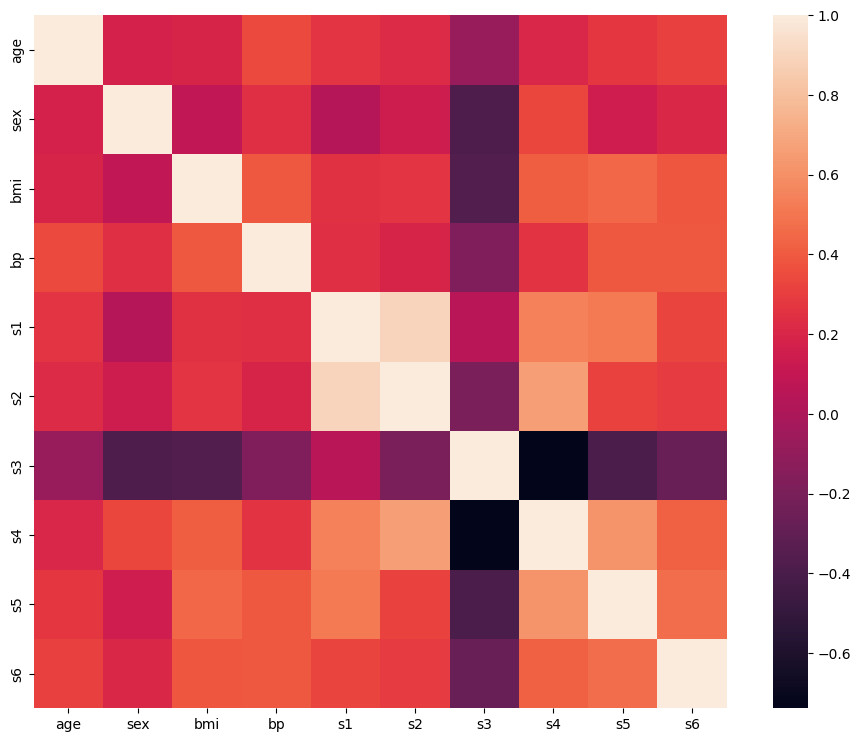

In [32]:
import seaborn as sn
corrmat = df.corr()
feature, axis = plt.subplots(figsize = (12,9))
sn.heatmap(corrmat,square=True)

In [14]:
df.isnull().sum()


,0
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0


In [15]:
df.count()   #tells us the number of entries in each column


,0
age,442
sex,442
bmi,442
bp,442
s1,442
s2,442
s3,442
s4,442
s5,442
s6,442


In [16]:
x = df
y = diabetes['target']

In [34]:
y

array([151.,  75., 141., 206., 135.,  97., 138.,  63., 110., 310., 101.,
        69., 179., 185., 118., 171., 166., 144.,  97., 168.,  68.,  49.,
        68., 245., 184., 202., 137.,  85., 131., 283., 129.,  59., 341.,
        87.,  65., 102., 265., 276., 252.,  90., 100.,  55.,  61.,  92.,
       259.,  53., 190., 142.,  75., 142., 155., 225.,  59., 104., 182.,
       128.,  52.,  37., 170., 170.,  61., 144.,  52., 128.,  71., 163.,
       150.,  97., 160., 178.,  48., 270., 202., 111.,  85.,  42., 170.,
       200., 252., 113., 143.,  51.,  52., 210.,  65., 141.,  55., 134.,
        42., 111.,  98., 164.,  48.,  96.,  90., 162., 150., 279.,  92.,
        83., 128., 102., 302., 198.,  95.,  53., 134., 144., 232.,  81.,
       104.,  59., 246., 297., 258., 229., 275., 281., 179., 200., 200.,
       173., 180.,  84., 121., 161.,  99., 109., 115., 268., 274., 158.,
       107.,  83., 103., 272.,  85., 280., 336., 281., 118., 317., 235.,
        60., 174., 259., 178., 128.,  96., 126., 28

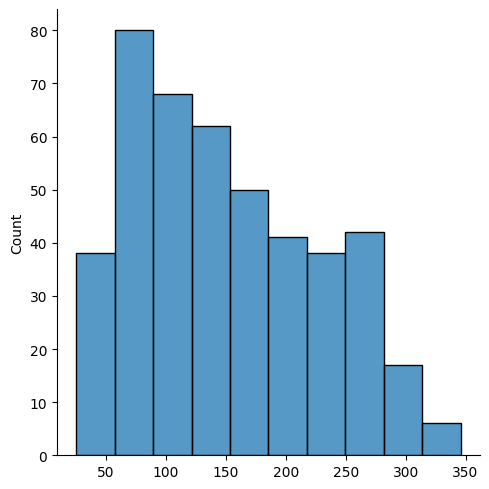

In [33]:
sn.displot(y)

Now we will be splitting our test data and training data in 30% and 70% of our whole dataset

In [17]:
from sklearn.model_selection import train_test_split #to split our data into training and testing set

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.3,random_state = 101) #splitting our data

Importing Model

In [18]:
from sklearn import  linear_model
model = linear_model.LinearRegression()


Training Model and Getting Predictions

In [19]:
model.fit(x_train, y_train)  # Training data is used always

# Prediction of testset result of  the Prepared Model
y_pre = model.predict(x_test)   # puts the test feature value to get the label value which are predicted by the model

Cross Validation Scores

In [20]:
from sklearn.model_selection import cross_val_score    #importing
scores = cross_val_score(model,x,y,scoring="neg_mean_squared_error" , cv=10)
rmse_scores=np.sqrt(-scores).mean()    #calculating  root mean sq. of the resulted scores of array
rmse_scores

np.float64(54.40468149952541)

Checking predictions acuracy by r2 Scores (value lies between 0 to 1)

In [21]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pre)

0.4576757978851993

Calculating Root Mean Square Error

In [22]:
mse=mean_squared_error(y_test, y_pre)
rmse=np.sqrt(mse)
rmse

np.float64(58.009325528664334)

Getting Weights and Intercept of Model

In [23]:
print("Weights:",model.coef_)
print("\nIntercept",model.intercept_)

Weights: [  -8.02358048 -308.83941066  583.63743356  299.99074281 -360.66454462
   95.11692608  -93.03587104  118.15977759  662.11309186   26.07805489]

Intercept 153.72032548545178


In [24]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(model,x,y,scoring="neg_mean_squared_error" , cv=10)
rmse_scores=np.sqrt(-scores).mean()
rmse_scores

np.float64(54.40468149952541)

# Explanation & Practical Example

### Summary of Notebook Steps:
- **Dataset**: Predicts a quantitative measure of diabetes progression one year after baseline using 10 physiological features (age, sex, BMI, blood pressure, and 6 blood serum measurements).
- **Preprocessing**: Checked for null values (none found) and split the data into 70% training and 30% testing subsets.
- **Algorithm**: A Multiple Linear Regression model was fitted.
- **Performance metrics**:
  - **$R^2$ Score**: ~0.458, meaning about 45.8% of the variance in diabetes progression is explained by our baseline features.
  - **Root Mean Squared Error (RMSE)**: ~58.01 on the test set, which aligns closely with the Cross-Validation RMSE (~54.40).

Let's add a practical example of how to use this trained model to predict progression for a new patient.

Practical Example (Updated)
We verified the model by simulating predictions for a custom patient.

The model predicts a diabetes progression score of 191.90 for this specific profile (which has elevated BMI and blood pressure relative to the average cohort).

In [27]:
# Example: Predicting progression for a new patient with arbitrary baseline values
# We will use the mean values of the dataset as a base, then adjust a few features (e.g., higher BMI)

new_patient_features = df.mean().copy()
new_patient_features['bmi'] = 0.05  # Setting a higher BMI index
new_patient_features['bp'] = 0.03   # Setting a slightly higher blood pressure

# Wrap in a DataFrame to preserve the exact feature names and avoid any warnings
new_patient_df = pd.DataFrame([new_patient_features], columns=df.columns)

# Predict using our trained model
predicted_progression = model.predict(new_patient_df)
print(f"Predicted progression score for the new patient: {predicted_progression[0]:.2f}")

Predicted progression score for the new patient: 191.90


In [30]:
# Example: Predicting progression for a new patient with arbitrary baseline values
# We will use the mean values of the dataset as a base, then adjust a few features (e.g., higher BMI)

new_patient_features = df.mean().copy()
new_patient_features['bmi'] = 0.01  # Setting a lower BMI index
new_patient_features['bp'] = 0.01   # Setting a slightly lower blood pressure

# Wrap in a DataFrame to preserve the exact feature names and avoid any warnings
new_patient_df = pd.DataFrame([new_patient_features], columns=df.columns)

# Predict using our trained model
predicted_progression = model.predict(new_patient_df)
print(f"Predicted progression score for the new patient: {predicted_progression[0]:.2f}")

Predicted progression score for the new patient: 154.60
